In [ ]:
# Section 1: packages, palette, and category colors (run once, first)
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.ticker import MaxNLocator


# general categorical palette (tab10 order)
subgen_palette = [
    '#1f77b4',  # blue
    '#ff7f0e',  # orange
    '#2ca02c',  # green
    '#d62728',  # red
    '#9467bd',  # purple
    '#e6ab02',  # gold
    '#e377c2',  # pink
    '#7f7f7f',  # grey
    '#bcbd22',  # olive
    '#17becf',  # cyan
]
# matplotlib-only replacement for sns.set_style('white') + sns.set_palette()
mpl.rcParams.update({'axes.facecolor': 'white', 'figure.facecolor': 'white',
                     'axes.grid': False})
mpl.rcParams['axes.prop_cycle'] = mpl.cycler(color=subgen_palette)

# semantic colors for expression classes, pulled from subgen_palette
palette_colors = {
    'always_expressed': subgen_palette[0],   # blue
    'subgen':           subgen_palette[2],    # green
    'never_expressed':  subgen_palette[3],    # red
    'possibly_subgen':  '#8fd18f',    # lightened subgen green — reads as subgen-family (Panel F only)
}

In [ ]:
# Section 2: Science-journal figure style (apply once; affects every plot)
mpl.rcParams.update({
    'font.family':        'sans-serif',
    'font.sans-serif':    ['Arial', 'Helvetica', 'DejaVu Sans'],
    'pdf.fonttype':        42,
    'ps.fonttype':         42,

    'font.size':           8,
    'axes.titlesize':      9,
    'axes.labelsize':      8,
    'xtick.labelsize':     7,
    'ytick.labelsize':     7,
    'legend.fontsize':     7,
    'figure.titlesize':    9,

    'text.color':          'black',
    'axes.labelcolor':     'black',
    'axes.edgecolor':      'black',
    'xtick.color':         'black',
    'ytick.color':         'black',
    'axes.linewidth':      0.6,
    'lines.linewidth':     1.0,
    'xtick.major.width':   0.6,
    'ytick.major.width':   0.6,

    'axes.spines.top':     False,
    'axes.spines.right':   False,

    'savefig.dpi':         600,
    'savefig.bbox':        'tight',
    'svg.fonttype':        'none',
})

# figure sizes in Science column widths (cm -> inches)
CM = 1/2.54
FIG_1COL = (5.7*CM, 5.0*CM)     # single column 5.7 cm
FIG_1_5  = (12.1*CM, 8.0*CM)    # 1.5 column
FIG_2COL = (18.4*CM, 10.0*CM)   # double column

SHOW_TITLES = False   # False for submission; True while developing

In [ ]:
# Local setup for the wcEcoli3 kernel (replaces the Colab paths).
# Run from notebooks/. Unspecified media -> minimal.
from pathlib import Path
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

NB_DIR    = Path.cwd()
DATA      = NB_DIR / 'data'                 # EcoCyc / UniProt / flow / RNA-seq / Schmidt
DATA_MIN  = DATA / '102126_minimal'         # simulation outputs, minimal media (default)
DATA_RICH = DATA / '102126_rich'            # simulation outputs, rich media
OUT_DIR   = NB_DIR / 'output' / 'fig2'      # all figures / tables / intermediates
assert DATA.is_dir(), f'run this notebook from notebooks/ (no data dir at {DATA})'
OUT_DIR.mkdir(parents=True, exist_ok=True)
PNG_DIR   = OUT_DIR / 'pngs'                 # every figure -> pngs/<name>.png
SVG_DIR   = OUT_DIR / 'svgs'                 #               + svgs/<name>.svg
PNG_DIR.mkdir(exist_ok=True)
SVG_DIR.mkdir(exist_ok=True)


def save_figure(fig, name, **kwargs):
    """Save one figure as pngs/<name>.png and svgs/<name>.svg (rcParams: 600 dpi, tight bbox)."""
    fig = fig if fig is not None else plt.gcf()
    fig.savefig(PNG_DIR / f'{name}.png', **kwargs)
    fig.savefig(SVG_DIR / f'{name}.svg', **kwargs)


def stacked_hist(ax, data, x, hue, hue_order=None, palette=None, bins='auto',
                 legend=True, edgecolor='white', alpha=0.75):
    """matplotlib stand-in for sns.histplot(..., hue=hue, multiple='stack').

    Matches seaborn: shared bin edges over all data, first hue level on
    TOP of the stack, legend listed in hue_order, alpha 0.75, ylabel 'Count'.
    """
    vals = pd.to_numeric(data[x], errors='coerce')
    keep = vals.notna() & data[hue].notna()
    vals, groups = vals[keep], data.loc[keep, hue]
    if hue_order is None:
        hue_order = list(pd.unique(groups))
    edges = np.histogram_bin_edges(vals, bins=bins)
    levels = list(hue_order)[::-1]               # bottom -> top
    colors = [palette[l] for l in levels] if palette is not None else None
    ax.hist([vals[groups == l] for l in levels], bins=edges, stacked=True,
            color=colors, label=levels, edgecolor=edgecolor, alpha=alpha)
    ax.set_ylabel('Count')
    if legend:
        handles, labels = ax.get_legend_handles_labels()
        by_label = dict(zip(labels, handles))
        ax.legend([by_label[l] for l in hue_order if l in by_label],
                  [l for l in hue_order if l in by_label], title=hue)
    return ax


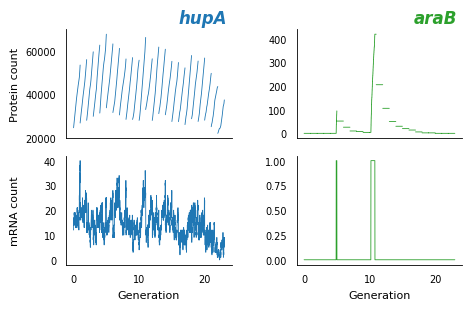

In [ ]:
# =====================================================================
# Fig 2 B–E — single-cell dynamics traces (hupA | araB), protein & mRNA
# Rows: protein (top) / mRNA (bottom). Cols: hupA (blue) / araB (green).
# Protein BROKEN at each generation boundary (partitions at division);
# mRNA CONTINUOUS (fast turnover, no clean division step).
# =====================================================================
GEN_WINDOW = None   # None = all generations; or an int (e.g. 12) to show fewer
TRIM_LAST  = True  # True = drop the final generation (use if sim ended mid-burst)

traces = pd.read_csv(f"{DATA_MIN}/subgen_monomer_dynamics/curated10/seed000025/traces.tsv",
                     sep='\t')
d = traces.copy()
if TRIM_LAST:
    d = d[d['generation'] < d['generation'].max()]
d = d.copy()
d['gen_cont'] = d['generation'] + d['gen_fraction'] - d['generation'].min()
if GEN_WINDOW is not None:
    d = d[d['gen_cont'] <= GEN_WINDOW]

# insert NaN rows at each generation boundary so the line breaks at divisions
def _break_at_generations(df, ycol):
    x, y = [], []
    for _, grp in df.groupby('generation', sort=True):
        x.extend(grp['gen_cont'].tolist() + [np.nan])   # NaN lifts the pen
        y.extend(grp[ycol].tolist() + [np.nan])
    return np.array(x), np.array(y)

genes = [('hupA', palette_colors['always_expressed'], 'Exponential: hupA'),
         ('araB', palette_colors['subgen'],           'Sub-generational: araB')]

fig, axes = plt.subplots(2, 2, figsize=FIG_1_5, sharex=True)
for col, (gene, color, title) in enumerate(genes):
    xp, yp = _break_at_generations(d, f'{gene}_monomer')      # protein: broken
    axes[0, col].plot(xp, yp, color=color, lw=0.6)
    axes[1, col].plot(d['gen_cont'], d[f'{gene}_mRNA'], color=color, lw=0.6)   # mRNA: continuous
    axes[0, col].text(0.97, 1.02, gene, transform=axes[0, col].transAxes,
                      ha='right', va='bottom', fontstyle='italic', fontweight='bold',
                      fontsize=12, color=color)
    if SHOW_TITLES:
        axes[0, col].set_title(title, color=color)
    axes[1, col].set_xlabel('Generation')

axes[0, 0].set_ylabel('Protein count')
axes[1, 0].set_ylabel('mRNA count')

fig.align_ylabels(axes[:, 0])

plt.tight_layout(w_pad=3.0)
save_figure(plt.gcf(), "fig2_BCDE_traces", transparent=True)
plt.show()

In [ ]:
# =====================================================================
# BUILD THE BASAL PER-GENE TABLE FROM TWO SOURCE FILES
# Maps def5 categories to the 3 the plots expect; possibly_subgen is
# MERGED INTO subgen (so I/J/histograms treat it as subgen). Panel F
# recovers the possibly_subgen split from def5 for display only.
# =====================================================================
import numpy as np
import pandas as pd

counts = pd.read_csv(f"{DATA_MIN}/subgen_definitions_all.tsv", sep='\t')
sub    = pd.read_csv(f"{DATA_MIN}/subgen_expression_table.tsv", sep='\t')

STATUS_MAP = {
    'not_subgen':      'always_expressed',
    'possibly_subgen': 'subgen',          # merged into subgen
    'subgen':          'subgen',
    'never_expressed': 'never_expressed',
}

# monomer_name and def5_CI_category now both come from the expression table
merged = counts[['gene_name', 'mean_protein_count']].merge(
    sub[['gene_name', 'monomer_name', 'def5_CI_category']],
    on='gene_name', how='inner', validate='one_to_one')
merged['expression_status_basal']   = merged['def5_CI_category'].map(STATUS_MAP)
merged['log2_mean_Protein_1_basal'] = np.log2(merged['mean_protein_count'] + 1)
assert merged['expression_status_basal'].notna().all(), 'unmapped def5 category'

out = merged[['gene_name', 'monomer_name', 'expression_status_basal',
              'mean_protein_count', 'log2_mean_Protein_1_basal']]
out.to_csv(f"{OUT_DIR}/subgen_monomers_basal.tsv", sep=',', index=True)
print('Built table:', len(out), 'rows ->', dict(out['expression_status_basal'].value_counts()))

Built table: 4311 rows -> {'always_expressed': np.int64(2264), 'subgen': np.int64(1910), 'never_expressed': np.int64(137)}


In [ ]:
merged.head()
#counts.head()


,gene_name,mean_protein_count,monomer_name,def5_CI_category,expression_status_basal,log2_mean_Protein_1_basal
0,EG10001,65.810481,ALARACEBIOSYN-MONOMER[c],not_subgen,always_expressed,6.062003
1,EG10002,85.350541,MODB-MONOMER[i],not_subgen,always_expressed,6.432133
2,EG10003,206.099992,EG10003-MONOMER[i],not_subgen,always_expressed,7.694184
3,EG10004,228.315655,EG10004-MONOMER[c],not_subgen,always_expressed,7.841191
4,EG10006,3.951411,DCUB-MONOMER[i],subgen,subgen,2.307840


In [ ]:
# =====================================================================
# LOAD INPUT TABLES + BUILD THE MERGED VALIDATION TABLE  (BASAL ONLY)
# Step 1: read the per-gene BASAL table (subgen_monomers_basal). It is
#   COMMA-separated with the row index in column 0, so it is read with
#   sep=',' and index_col=0. It supplies gene_name, the
#   expression_status_basal class, and log2_mean_Protein_1_basal.
# Step 2: read the Schmidt 2015 validation table (tab-separated); it
#   supplies EcoCycID and the measured 'Glucose' protein counts.
# Step 3: LEFT-merge the two on gene_name == EcoCycID to make
#   subgen_w_val_data (simulation rows + matched validation columns).
#   fillna(0) sets validation values to 0 for genes Schmidt lacks.
# Files are read from notebooks/data/ (local copies).
# Feeds F (via subgen_counts_basal) and I + J (via subgen_w_val_data).
# =====================================================================
basal_path = f"{OUT_DIR}/subgen_monomers_basal.tsv"
subgen_counts_basal = pd.read_csv(basal_path,
                                  sep = ',',
                                  index_col = 0)
schmidt_path = f"{DATA}/schmidt2015_javier_table.tsv"
schmidt_df = pd.read_csv(schmidt_path, sep = '\t')


In [ ]:
# EG11314 collision: purB (P0AB89) and ade/adeD (P31441) both mapped to EG11314.
# EG11314 is truly purB; remap the adenine-deaminase row to its correct EcoCyc ID.
schmidt_df.loc[(schmidt_df['EcoCycID'] == 'EG11314') & (schmidt_df['GeneName'] == 'ade'),
               'EcoCycID'] = 'EG11692'   # adeD, adenine deaminase (b3665), verified from EcoCyc all-genes

In [ ]:
#Merge, this is just monomer counts from simulation and schmidt data
subgen_w_val_data = subgen_counts_basal.merge(schmidt_df, left_on = 'gene_name', right_on = 'EcoCycID', how = 'left').fillna(0)

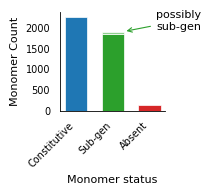

In [ ]:
# =====================================================================
# PANEL F — expression classes (BASAL). 3 bars: Constitutive / Sub-gen /
# Absent. possibly_subgen is merged into subgen in the data; here (Panel F
# ONLY) the Sub-gen bar is split into subgen (solid) + possibly_subgen
# (lightened green cap) recovered from the def5 table. This cell must run
# BEFORE the "drop possibly_subgen" cell, which removes those genes
# downstream. Reads: subgen_counts_basal, palette_colors, DATA_DIR.
# =====================================================================
BAR_W = 0.6   # bar width (matplotlib default 0.8; lower = narrower)

# counts from the plotted data (3 categories)
vc       = subgen_counts_basal['expression_status_basal'].value_counts()
n_const  = int(vc.get('always_expressed', 0))
n_subtot = int(vc.get('subgen', 0))          # includes possibly_subgen
n_absent = int(vc.get('never_expressed', 0))

# recover the possibly_subgen portion (def5), within the same gene set
_sub_def5  = pd.read_csv(f"{DATA_MIN}/subgen_expression_table.tsv", sep='\t')
_pos_genes = set(_sub_def5.loc[_sub_def5['def5_CI_category'] == 'possibly_subgen', 'gene_name'])
n_poss     = int(subgen_counts_basal['gene_name'].isin(_pos_genes).sum())
n_subpure  = n_subtot - n_poss

fig, ax = plt.subplots(figsize=FIG_1COL)
ax.bar(0, n_const,   width=BAR_W, color=palette_colors['always_expressed'], edgecolor='white', linewidth=0.5)
ax.bar(1, n_subpure, width=BAR_W, color=palette_colors['subgen'],           edgecolor='white', linewidth=0.5)
ax.bar(1, n_poss,    width=BAR_W, bottom=n_subpure, color=palette_colors['possibly_subgen'],
       edgecolor='white', linewidth=0.5, label='possibly sub-gen')
ax.bar(2, n_absent,  width=BAR_W, color=palette_colors['never_expressed'],  edgecolor='white', linewidth=0.5)

ax.set_xticks([0, 1, 2])
ax.set_xticklabels(['Constitutive', 'Sub-gen', 'Absent'], rotation=45, ha='right')
ax.set_ylabel('Monomer Count')
ax.set_xlabel('Monomer status')

# short arrow -> possibly_subgen cap, label up-right (matches reference layout)
_cap_top   = n_subtot                 # top of the green cap (= full sub-gen total)
_cap_right = 1 + BAR_W/2              # right edge of the Sub-gen bar (tracks BAR_W)

ax.annotate('possibly\nsub-gen',
            xy=(_cap_right, _cap_top),           # tip: top-right corner of the cap
            xytext=(2.8, _cap_top + 0),        # label: below-right
            va='bottom', ha='center',
            color='black',
            arrowprops=dict(arrowstyle='->', color=palette_colors['subgen'], lw=0.8))

plt.tight_layout()
save_figure(plt.gcf(), "subgen_constitutive_absent_counts", transparent=True)

In [ ]:

# DROP possibly_subgen GENES FROM ALL DOWNSTREAM PLOTS
# Panel F (above) KEEPS possibly_subgen as the lighter-green cap.
# Everything below EXCLUDES them. Run Panel F BEFORE this cell.

_sub_def5  = pd.read_csv(f"{DATA_MIN}/subgen_expression_table.tsv", sep='\t')
_pos_genes = set(_sub_def5.loc[_sub_def5['def5_CI_category'] == 'possibly_subgen', 'gene_name'])

_n_before = len(subgen_counts_basal)
subgen_counts_basal = subgen_counts_basal[~subgen_counts_basal['gene_name'].isin(_pos_genes)].copy()
subgen_w_val_data   = subgen_w_val_data[~subgen_w_val_data['gene_name'].isin(_pos_genes)].copy()
print(f'Dropped possibly_subgen: {_n_before} -> {len(subgen_counts_basal)} genes '
      f'({_n_before - len(subgen_counts_basal)} removed)')

Dropped possibly_subgen: 4311 -> 4249 genes (62 removed)


In [ ]:
monomers_of_interest = ['GLYCDEH-MONOMER[c]',  # gldA
						'BETAGALACTOSID-MONOMER[c]',  # lacZ
						'RIBULOKIN-MONOMER[c]',  # araB
						'BAES-MONOMER[i]',  # baeS
						'G6504-MONOMER[o]',  # gfcE
						'EG11250-MONOMER[c]',  # chpS
						'EG11222-MONOMER[c]',  # alkA
						'G7263-MONOMER[c]',  # murQ
						'EG11249-MONOMER[c]',  # mazF const
						'EG10466-MONOMER[c]'  # hupA const
						]

monomers_of_interest_name_dict = {'GLYCDEH-MONOMER[c]': 'gldA',
						'BETAGALACTOSID-MONOMER[c]': 'lacZ',
						'RIBULOKIN-MONOMER[c]': 'araB',
						'BAES-MONOMER[i]': 'baeS',
						'G6504-MONOMER[o]': 'gfcE',
						'EG11250-MONOMER[c]': 'chpS',
						'EG11222-MONOMER[c]': 'alkA',
						'G7263-MONOMER[c]': 'murQ',
						'EG11249-MONOMER[c]': 'mazF',
						'EG10466-MONOMER[c]': 'hupA'
								  }

In [ ]:
subgen_counts_basal.columns

Index(['gene_name', 'monomer_name', 'expression_status_basal',
       'mean_protein_count', 'log2_mean_Protein_1_basal'],
      dtype='object')

In [ ]:
subgen_w_val_data['log2_Validation_Protein_1'] = np.log2(subgen_w_val_data['Glucose'] +1)

In [ ]:
print(subgen_w_val_data['expression_status_basal'].value_counts())

expression_status_basal
always_expressed    2264
subgen              1848
never_expressed      137
Name: count, dtype: int64


In the fixed schmidt_df: EG11314 → purB (Glucose 1933), EG11692 → ade (Glucose 5). Two separate rows, two separate IDs.
Both are in the model's gene list (EG11314 and EG11692 each appear once in the model counts), so both survive the left-merge.
In the merged subgen_w_val_data:
EG11314 (purB) → Glucose = 1933
EG11692 (adeD/adenine deaminase) → Glucose = 5

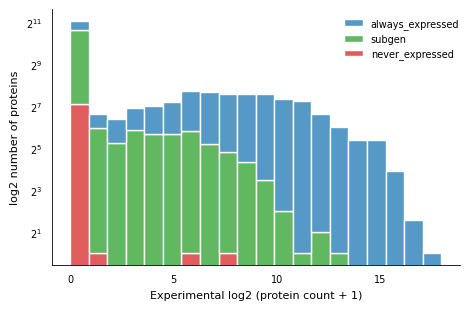

In [ ]:
# =====================================================================
# Validation monomer counts distribution — stacked histogram
# X: log2(validation protein count + 1) from Schmidt 2015 proteomics.
# Stacked by expression class (always_expressed / subgen / never_expressed),
# colored via palette_colors. Y-axis on a log2 scale to reveal low-count
# bins (note: empty bins are not drawn, and bar heights are not
# proportional on a log axis — state "log scale" in the caption).
# Reads subgen_w_val_data, so possibly_subgen genes are already excluded.
# =====================================================================
fig, ax = plt.subplots(figsize=FIG_1_5)
stacked_hist(ax, subgen_w_val_data,
             x='log2_Validation_Protein_1',
             hue='expression_status_basal',
             palette=palette_colors)

legend = ax.get_legend()
if legend:
    legend.set_bbox_to_anchor((1.02, 1.0))
    legend.set_frame_on(False)
    legend.set_title(None)

ax.set_yscale('log', base=2)
if SHOW_TITLES:
    ax.set_title('Validation monomer counts distribution')
ax.set_xlabel('Experimental log2 (protein count + 1)')
ax.set_ylabel('log2 number of proteins')
ax.set_xticks(np.arange(0, 20, 5))

plt.tight_layout()
save_figure(plt.gcf(), "Validation_monomer_counts_distribution", transparent=True)

In [ ]:
zero_protein_gene_ids = subgen_w_val_data['gene_name'][subgen_w_val_data['log2_Validation_Protein_1']<=1].unique()

In [ ]:
# genes drawn in red (never_expressed) that have real validation protein
red = subgen_w_val_data[subgen_w_val_data['expression_status_basal'] == 'never_expressed'].copy()

# the middle-x ones: measured protein above the x≈0 pile-up
mid = red[red['log2_Validation_Protein_1'] > 0.5].sort_values('log2_Validation_Protein_1')

cols = [c for c in ['gene_name', 'monomer_name', 'log2_Validation_Protein_1',
                    'mean_protein_count', 'def5_CI_category'] if c in subgen_w_val_data.columns]
print(f'{len(red)} never_expressed total, {len(mid)} with log2_val > 0.5')
print(mid[cols].to_string(index=False))

137 never_expressed total, 3 with log2_val > 0.5
gene_name         monomer_name  log2_Validation_Protein_1  mean_protein_count
  EG11054      UHPT-MONOMER[i]                   1.000000                 0.0
  EG11075 XYLULOKIN-MONOMER[c]                   5.614710                 0.0
  EG11074   XYLISOM-MONOMER[c]                   8.027906                 0.0


In [ ]:
# --- your current J histogram data ---
_pos_genes_all = set(pd.read_csv(f"{DATA_MIN}/subgen_expression_table.tsv", sep='\t')
                     .loc[lambda t: t['def5_CI_category'] == 'possibly_subgen', 'gene_name'])

print('=== YOUR PLOT (subgen_w_val_data) ===')
print('total genes plotted :', len(subgen_w_val_data))
print('possibly_subgen left:', subgen_w_val_data['gene_name'].isin(_pos_genes_all).sum())  # expect 0
print('x range             :', round(subgen_w_val_data['log2_Validation_Protein_1'].min(),2),
      '->', round(subgen_w_val_data['log2_Validation_Protein_1'].max(),2))
print('by class            :', dict(subgen_w_val_data['expression_status_basal'].value_counts()))
print()
print('=== REFERENCE (panel B) ===')
print('reference n         : 2107 + 2281 =', 2107 + 2281)
print('your total + 52     :', len(subgen_w_val_data) + 52)

=== YOUR PLOT (subgen_w_val_data) ===
total genes plotted : 4249
possibly_subgen left: 0
x range             : 0.0 -> 17.95
by class            : {'always_expressed': np.int64(2264), 'subgen': np.int64(1848), 'never_expressed': np.int64(137)}

=== REFERENCE (panel B) ===
reference n         : 2107 + 2281 = 4388
your total + 52     : 4301


In [ ]:
# how many genes are in each upstream frame?
print('subgen_counts_basal  :', len(subgen_counts_basal), '(after possibly_subgen drop)')
print('subgen_w_val_data    :', len(subgen_w_val_data))
print()
# does the merge lose or duplicate anything?
print('unique gene_name in w_val:', subgen_w_val_data['gene_name'].nunique())
print('duplicated gene_name?    :', subgen_w_val_data['gene_name'].duplicated().sum())
print()
# reconstruct the pre-drop total
print('pre-drop total (should be +52):', len(subgen_w_val_data) + 52)

subgen_counts_basal  : 4249 (after possibly_subgen drop)
subgen_w_val_data    : 4249

unique gene_name in w_val: 4249
duplicated gene_name?    : 0

pre-drop total (should be +52): 4301


Quadrant (<= 200 counts on both): 2699 genes -> {'subgen': np.int64(1792), 'always_expressed': np.int64(771), 'never_expressed': np.int64(136)}


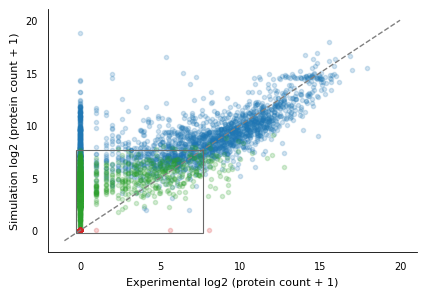

In [ ]:
compare_col_1 = 'log2_mean_Protein_1_basal'
compare_col_2 = 'log2_Validation_Protein_1'
fig, ax = plt.subplots(figsize=FIG_1_5)

for status in ['always_expressed', 'subgen', 'never_expressed']:
    m = subgen_w_val_data['expression_status_basal'] == status
    ax.scatter(subgen_w_val_data.loc[m, compare_col_2],
               subgen_w_val_data.loc[m, compare_col_1],
               c=palette_colors[status], marker='.', alpha=0.2)

ax_min = np.floor(min(ax.get_xlim()[0], ax.get_ylim()[0]))
ax_max = np.ceil(max(ax.get_xlim()[1], ax.get_ylim()[1]))
ax.plot([ax_min, ax_max], [ax_min, ax_max], color='grey', linestyle='--')

# --- computed "low in both" quadrant: <= PROT_BOX_THR counts on BOTH axes ---
PROT_BOX_THR = 200
box_edge = np.log2(PROT_BOX_THR + 1)           # log2(201)~7.65
pad = -0.3                                       # nudge off the origin so it clears x=0 / diagonal
ax.add_patch(Rectangle((pad, pad), box_edge - pad, box_edge - pad,
                       fill=False, edgecolor='dimgray', linewidth=0.8, zorder=5))

_inbox = ((subgen_w_val_data[compare_col_2] <= box_edge) &
          (subgen_w_val_data[compare_col_1] <= box_edge))
print(f"Quadrant (<= {PROT_BOX_THR} counts on both): {int(_inbox.sum())} genes ->",
      dict(subgen_w_val_data.loc[_inbox, 'expression_status_basal'].value_counts()))

if SHOW_TITLES:
    ax.set_title('Simulation vs. Validation')
ax.set_ylabel("Simulation log2 (protein count + 1)")
ax.set_xlabel("Experimental log2 (protein count + 1)")
ax.set_xticks(np.arange(0, 21, 5))
ax.set_yticks(np.arange(0, 21, 5))

save_figure(plt.gcf(), "simulation_vs_validation", transparent=True)

In [ ]:
box_edge = np.log2(200 + 1)
inbox = ((subgen_w_val_data[compare_col_2] <= box_edge) &
         (subgen_w_val_data[compare_col_1] <= box_edge))
sub_mask = subgen_w_val_data['expression_status_basal'] == 'subgen'
n_sub_in  = int((inbox & sub_mask).sum())
n_sub_tot = int(sub_mask.sum())
print(f"subgen in box: {n_sub_in} / {n_sub_tot} = {100*n_sub_in/n_sub_tot:.1f}%")


subgen in box: 1792 / 1848 = 97.0%


In [ ]:
print('possibly_subgen still in frame:', subgen_w_val_data['gene_name'].isin(_pos_genes).sum())  # want 0
print('subgen total in frame        :', (subgen_w_val_data['expression_status_basal']=='subgen').sum())  # want 1859
print('subgen inside box            :', ((subgen_w_val_data['expression_status_basal']=='subgen') & _inbox).sum())  # 1794

possibly_subgen still in frame: 0
subgen total in frame        : 1848
subgen inside box            : 1792


In [ ]:
path_monomer_dist = f"{DATA_MIN}/subgen_protein_distribution_new_monomers_per_gen.tsv"
monomer_dist_df = pd.read_csv(path_monomer_dist,  sep = '\t')

In [ ]:
monomer_dist_df.head(5)

,cell_id,GLYCDEH-MONOMER[c],BETAGALACTOSID-MONOMER[c],RIBULOKIN-MONOMER[c],BAES-MONOMER[i],G6504-MONOMER[o],EG11250-MONOMER[c],EG11222-MONOMER[c],G7263-MONOMER[c],EG11249-MONOMER[c],EG10466-MONOMER[c]
0,/scratch/users/aj0204/wcEcoli_out/20261021.112...,0,0,142,-3,149,-1,0,0,50,24692
1,/scratch/users/aj0204/wcEcoli_out/20261021.112...,0,0,0,-4,-5,30,0,378,13,29170
2,/scratch/users/aj0204/wcEcoli_out/20261021.112...,0,0,0,0,-2,19,98,0,31,31398
3,/scratch/users/aj0204/wcEcoli_out/20261021.112...,0,0,0,56,-2,15,201,0,106,29208
4,/scratch/users/aj0204/wcEcoli_out/20261021.112...,0,0,0,2,-1,-1,-6,0,0,22423


hupA: n=1296  negatives clipped to 0: 0  exact zeros: 0  min=200  max=43713
araB: n=1296  negatives clipped to 0: 1  exact zeros: 1230  min=-1  max=819


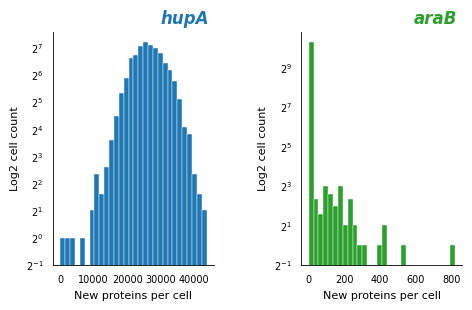

In [ ]:
# =====================================================================
# Fig 2 G & H — two-panel figure (hupA | araB), new-proteins-per-cell
# Colors from palette_colors: hupA (exponential) = blue; araB (sub-gen) = green.
#
# DATA NOTES (checked):
#  - "New proteins per cell" is an end-minus-start net change per generation,
#    so it can in principle be negative (degradation > production).
#  - CLIPPING: .clip(lower=0) sets negative values to 0 (positives untouched).
#    Checked on these genes: hupA has 0 negatives, araB has 1 (value -1) out of
#    1,296 cells. The clip therefore moves 1 cell into araB's zero bar
#    (1,230 -> 1,231), which is invisible on the log axis. No artifact.
#  - hupA minimum is 200 (no true zeros). The few low-count bars are real
#    low-production cells; the one at 200 sits in the first bin near x = 0.
#
# PLOT NOTES:
#  - SAME binning rule for both panels: N_BINS equal-width bins spanning
#    0 -> that gene's max. The two genes differ ~50x in range, so the same
#    bin COUNT (not width) keeps bar widths visually matched. 'auto' is avoided:
#    Freedman-Diaconis uses the IQR, which collapses for araB (zero-spiked,
#    heavy tail) and gives hundreds of skinny bars.
#  - Y-axis log2 to reveal sparse far-right bars (state "log scale" in caption).
#    Empty bins cannot be drawn on a log axis (gaps = zero cells).
#    ylim bottom = 0.5 so single-cell bars (log2(1) = 0) are drawn visibly.
#  - Gene name shown as an in-panel label (independent of SHOW_TITLES).
# =====================================================================
N_BINS = 30   # applied identically to both genes

df_long = monomer_dist_df.melt(
    value_vars=monomers_of_interest, var_name='Monomer', value_name='Count_gen')
df_long['Gene'] = df_long['Monomer'].map(monomers_of_interest_name_dict)

# report what the clip will touch, per plotted gene, before applying it
for g in ['hupA', 'araB']:
    r = df_long.loc[df_long['Gene'] == g, 'Count_gen'].dropna()
    print(f'{g}: n={len(r)}  negatives clipped to 0: {(r < 0).sum()}  '
          f'exact zeros: {(r == 0).sum()}  min={r.min()}  max={r.max()}')

df_long['Count_gen'] = df_long['Count_gen'].clip(lower=0)

fig, axes = plt.subplots(1, 2, figsize=FIG_1_5)

panels = [('hupA', palette_colors['always_expressed'], 'Exponential: hupA'),
          ('araB', palette_colors['subgen'],           'Sub-generational: araB')]

for ax, (gene, color, title) in zip(axes, panels):
    x = df_long.loc[df_long['Gene'] == gene, 'Count_gen'].dropna()

    bins = np.linspace(0, x.max(), N_BINS + 1)   # same rule for every gene
    ax.hist(x, bins=bins, color=color, edgecolor='white', linewidth=0.3)

    ax.xaxis.set_major_locator(MaxNLocator(nbins=5))
    ax.set_yscale('log', base=2)
    ax.set_ylim(bottom=0.5)                  # keeps count = 1 bars visible
    ax.spines['top'].set_visible(False)      # explicit despine (robust to run order)
    ax.spines['right'].set_visible(False)
    ax.text(0.97, 1.02, gene, transform=ax.transAxes,
            ha='right', va='bottom', fontstyle='italic', fontweight='bold',
            fontsize=12, color=color)
    if SHOW_TITLES:
        ax.set_title(title, color=color)
    ax.set_xlabel('New proteins per cell')
    ax.set_ylabel('Log2 cell count')

plt.tight_layout(w_pad=4.0)
save_figure(plt.gcf(), "fig2_GH_panel", transparent=True)
plt.show()